In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

matches = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "matches_cleaned.csv"
)

deliveries = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "deliveries_cleaned.csv"
)

print("Matches Shape:", matches.shape)
print("Deliveries Shape:", deliveries.shape)

Matches Shape: (1095, 20)
Deliveries Shape: (260920, 17)


In [2]:
print("Extra Types in Dataset:")

print(deliveries["extras_type"].value_counts(dropna=False))

Extra Types in Dataset:
extras_type
NaN        246795
wides        8380
legbyes      4001
noballs      1069
byes          673
penalty         2
Name: count, dtype: int64


In [3]:
deliveries["balls_faced"] = (
    deliveries["extras_type"] != "wides"
).astype(int)
print(deliveries[["extras_type", "balls_faced"]].head(10))

print("\nTotal Balls Faced:", deliveries["balls_faced"].sum())

print("Total Wide Deliveries:",
      (deliveries["extras_type"] == "wides").sum())

  extras_type  balls_faced
0     legbyes            1
1         NaN            1
2       wides            0
3         NaN            1
4         NaN            1
5         NaN            1
6     legbyes            1
7         NaN            1
8         NaN            1
9         NaN            1

Total Balls Faced: 252540
Total Wide Deliveries: 8380


In [4]:
batting_stats = deliveries.groupby("batter").agg(
    total_runs=("batsman_runs", "sum"),
    balls_faced=("balls_faced", "sum")
).reset_index()

print(batting_stats.head(10))

           batter  total_runs  balls_faced
0  A Ashish Reddy         280          193
1        A Badoni         634          473
2      A Chandila           4            7
3        A Chopra          53           71
4     A Choudhary          25           20
5     A Dananjaya           4            5
6      A Flintoff          62           53
7        A Kamboj           2            2
8        A Kumble          35           47
9       A Manohar         231          174


In [5]:
batting_stats["strike_rate"] = (
    batting_stats["total_runs"] /
    batting_stats["balls_faced"]
) * 100

batting_stats["strike_rate"] = batting_stats["strike_rate"].round(2)

print(batting_stats.head(10))

           batter  total_runs  balls_faced  strike_rate
0  A Ashish Reddy         280          193       145.08
1        A Badoni         634          473       134.04
2      A Chandila           4            7        57.14
3        A Chopra          53           71        74.65
4     A Choudhary          25           20       125.00
5     A Dananjaya           4            5        80.00
6      A Flintoff          62           53       116.98
7        A Kamboj           2            2       100.00
8        A Kumble          35           47        74.47
9       A Manohar         231          174       132.76


In [8]:
qualified_batsmen = batting_stats[
    batting_stats["balls_faced"] >= 500
]

top_10_strike_rate = qualified_batsmen.sort_values(
    by="strike_rate",
    ascending=False
).head(10)

print(top_10_strike_rate)

              batter  total_runs  balls_faced  strike_rate
39        AD Russell        2488         1423       174.84
208        H Klaasen         993          590       168.31
561        SP Narine        1534          925       165.84
323   LS Livingstone         939          578       162.46
396         N Pooran        1769         1092       162.00
485       RM Patidar         799          503       158.85
203       GJ Maxwell        2772         1769       156.70
633         V Sehwag        2728         1755       155.44
70   Abhishek Sharma        1377          887       155.24
557       SO Hetmyer        1243          812       153.08


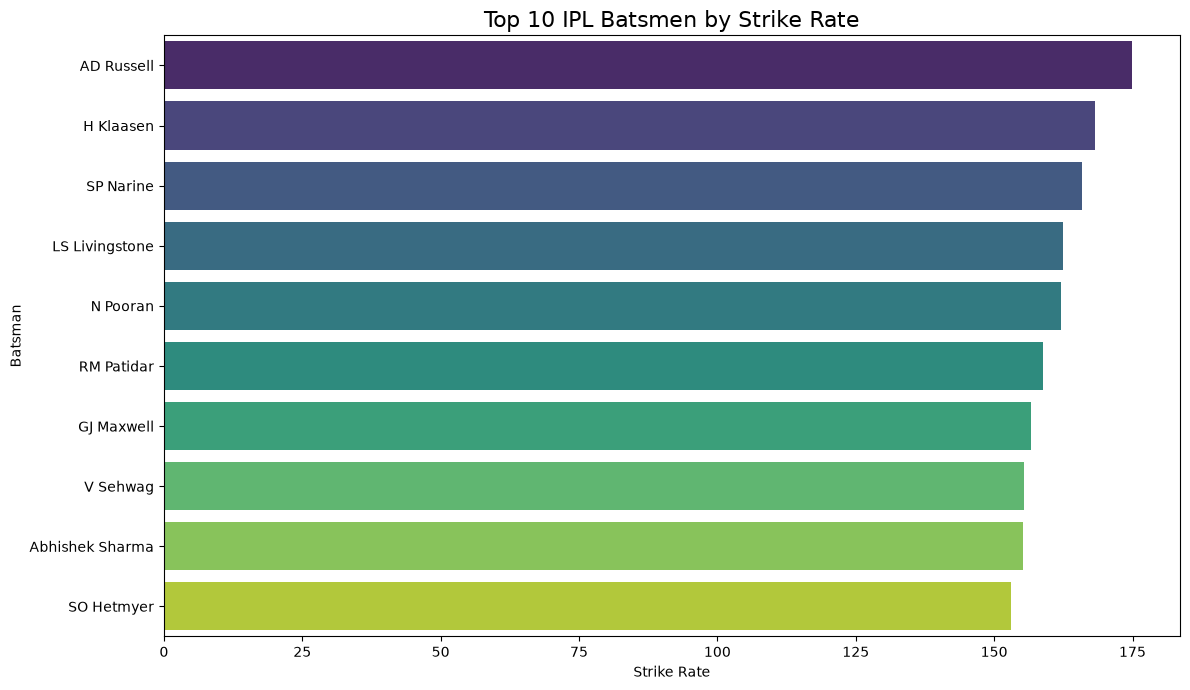

In [9]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_strike_rate,
    x="strike_rate",
    y="batter",
    hue="batter",
    palette="viridis",
    legend=False
)

plt.title("Top 10 IPL Batsmen by Strike Rate", fontsize=16)
plt.xlabel("Strike Rate")
plt.ylabel("Batsman")

plt.tight_layout()
plt.show()

In [10]:
top_10_run_scorers = batting_stats.sort_values(
    by="total_runs",
    ascending=False
).head(10)

print(top_10_run_scorers)

             batter  total_runs  balls_faced  strike_rate
631         V Kohli        8014         6069       132.05
512        S Dhawan        6769         5326       127.09
477       RG Sharma        6630         5057       131.11
147       DA Warner        6567         4702       139.66
546        SK Raina        5536         4046       136.83
374        MS Dhoni        5243         3812       137.54
30   AB de Villiers        5181         3411       151.89
124        CH Gayle        4997         3346       149.34
501      RV Uthappa        4954         3801       130.33
282      KD Karthik        4843         3580       135.28


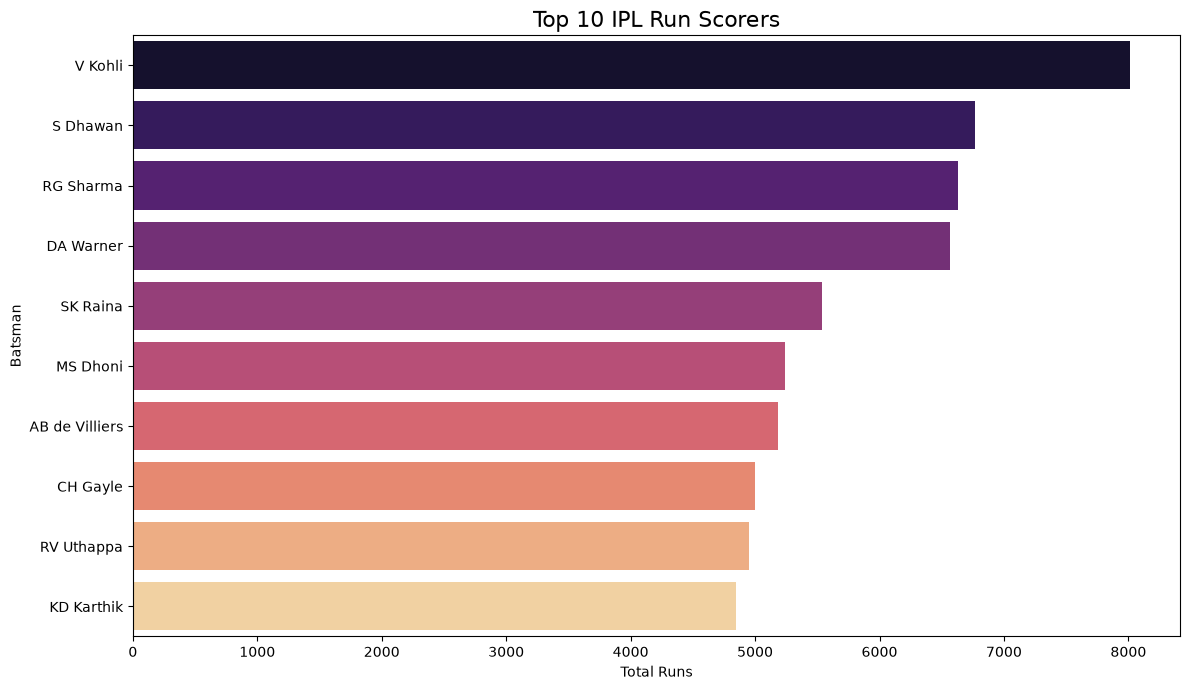

In [11]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_run_scorers,
    x="total_runs",
    y="batter",
    hue="batter",
    palette="magma",
    legend=False
)

plt.title("Top 10 IPL Run Scorers", fontsize=16)
plt.xlabel("Total Runs")
plt.ylabel("Batsman")

plt.tight_layout()
plt.show()

In [12]:
print(deliveries.columns.tolist())

['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder', 'balls_faced']


In [13]:
print(deliveries[
    ["bowler", "total_runs", "batsman_runs", "extra_runs",
     "extras_type", "is_wicket"]
].head(10))

    bowler  total_runs  batsman_runs  extra_runs extras_type  is_wicket
0  P Kumar           1             0           1     legbyes          0
1  P Kumar           0             0           0         NaN          0
2  P Kumar           1             0           1       wides          0
3  P Kumar           0             0           0         NaN          0
4  P Kumar           0             0           0         NaN          0
5  P Kumar           0             0           0         NaN          0
6  P Kumar           1             0           1     legbyes          0
7   Z Khan           0             0           0         NaN          0
8   Z Khan           4             4           0         NaN          0
9   Z Khan           4             4           0         NaN          0


In [14]:
deliveries["runs_conceded"] = deliveries["total_runs"]

deliveries.loc[
    deliveries["extras_type"].isin(["byes", "legbyes", "penalty"]),
    "runs_conceded"
] = deliveries["batsman_runs"]

In [15]:
print(deliveries[
    ["extras_type", "batsman_runs", "total_runs", "runs_conceded"]
].head(15))

   extras_type  batsman_runs  total_runs  runs_conceded
0      legbyes             0           1              0
1          NaN             0           0              0
2        wides             0           1              1
3          NaN             0           0              0
4          NaN             0           0              0
5          NaN             0           0              0
6      legbyes             0           1              0
7          NaN             0           0              0
8          NaN             4           4              4
9          NaN             4           4              4
10         NaN             6           6              6
11         NaN             4           4              4
12         NaN             0           0              0
13         NaN             0           0              0
14         NaN             0           0              0


In [16]:
deliveries["legal_ball"] = (
    ~deliveries["extras_type"].isin(["wides", "noballs"])
).astype(int)

In [17]:
print(deliveries[
    ["extras_type", "legal_ball"]
].head(15))

print("\nTotal Legal Balls:", deliveries["legal_ball"].sum())

print("Total Wides:",
      (deliveries["extras_type"] == "wides").sum())

print("Total No-balls:",
      (deliveries["extras_type"] == "noballs").sum())

   extras_type  legal_ball
0      legbyes           1
1          NaN           1
2        wides           0
3          NaN           1
4          NaN           1
5          NaN           1
6      legbyes           1
7          NaN           1
8          NaN           1
9          NaN           1
10         NaN           1
11         NaN           1
12         NaN           1
13         NaN           1
14         NaN           1

Total Legal Balls: 251471
Total Wides: 8380
Total No-balls: 1069


In [18]:
bowling_stats = deliveries.groupby("bowler").agg(
    runs_conceded=("runs_conceded", "sum"),
    legal_balls=("legal_ball", "sum")
).reset_index()

print(bowling_stats.head(10))

           bowler  runs_conceded  legal_balls
0  A Ashish Reddy            396          262
1        A Badoni             36           25
2      A Chandila            242          234
3     A Choudhary            144          101
4     A Dananjaya             47           24
5      A Flintoff            105           66
6        A Kamboj            114           60
7        A Kumble           1058          965
8        A Mishra           4145         3371
9        A Mithun            472          288


In [19]:
bowling_stats["economy_rate"] = (
    bowling_stats["runs_conceded"] * 6 /
    bowling_stats["legal_balls"]
)

bowling_stats["economy_rate"] = (
    bowling_stats["economy_rate"].round(2)
)

print(bowling_stats.head(10))

           bowler  runs_conceded  legal_balls  economy_rate
0  A Ashish Reddy            396          262          9.07
1        A Badoni             36           25          8.64
2      A Chandila            242          234          6.21
3     A Choudhary            144          101          8.55
4     A Dananjaya             47           24         11.75
5      A Flintoff            105           66          9.55
6        A Kamboj            114           60         11.40
7        A Kumble           1058          965          6.58
8        A Mishra           4145         3371          7.38
9        A Mithun            472          288          9.83


In [20]:
qualified_bowlers = bowling_stats[
    bowling_stats["legal_balls"] >= 500
]

top_10_economy = qualified_bowlers.sort_values(
    by="economy_rate",
    ascending=True
).head(10)

print(top_10_economy)

              bowler  runs_conceded  legal_balls  economy_rate
7           A Kumble           1058          965          6.58
263   M Muralitharan           1706         1528          6.70
446        SP Narine           4582         4081          6.74
130       DL Vettori            879          777          6.79
398      Rashid Khan           3267         2872          6.83
176          J Botha            800          694          6.92
138         DW Steyn           2523         2182          6.94
368         R Sharma           1086          928          7.02
288           MM Ali            893          758          7.07
163  Harbhajan Singh           4030         3416          7.08


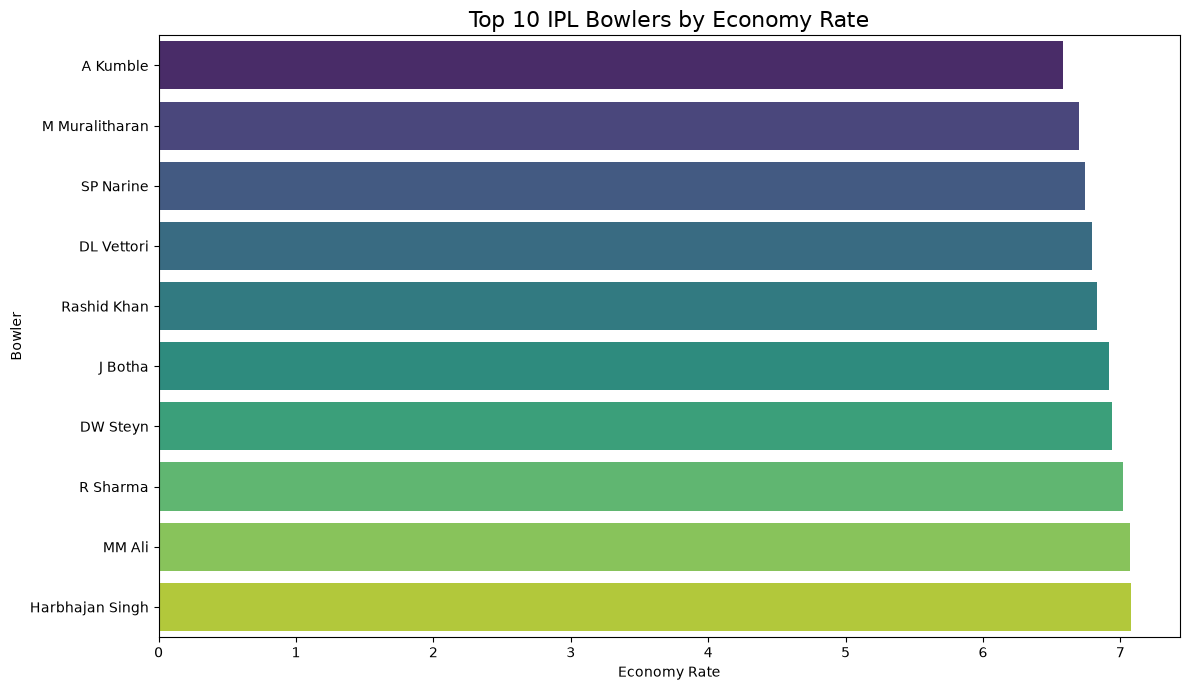

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_economy,
    x="economy_rate",
    y="bowler",
    hue="bowler",
    palette="viridis",
    legend=False
)

plt.title("Top 10 IPL Bowlers by Economy Rate", fontsize=16)
plt.xlabel("Economy Rate")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

In [22]:
print("Dismissal Types:")
print(deliveries["dismissal_kind"].value_counts(dropna=False))

Dismissal Types:
dismissal_kind
NaN                      247970
caught                     8063
bowled                     2212
run out                    1114
lbw                         800
caught and bowled           367
stumped                     358
retired hurt                 15
hit wicket                   15
obstructing the field         3
retired out                   3
Name: count, dtype: int64


In [23]:
bowler_wicket_types = [
    "caught",
    "bowled",
    "lbw",
    "caught and bowled",
    "stumped",
    "hit wicket"
]

In [24]:
bowler_wickets = deliveries[
    deliveries["dismissal_kind"].isin(bowler_wicket_types)
].groupby("bowler").agg(
    wickets=("dismissal_kind", "count")
).reset_index()

print(bowler_wickets.head(10))

           bowler  wickets
0  A Ashish Reddy       18
1        A Badoni        2
2      A Chandila       11
3     A Choudhary        5
4      A Flintoff        2
5        A Kamboj        2
6        A Kumble       45
7        A Mishra      174
8        A Mithun        7
9         A Nehra      106


In [25]:
bowling_stats = bowling_stats.merge(
    bowler_wickets,
    on="bowler",
    how="left"
)

bowling_stats["wickets"] = (
    bowling_stats["wickets"].fillna(0).astype(int)
)

print(bowling_stats.head(10))

           bowler  runs_conceded  legal_balls  economy_rate  wickets
0  A Ashish Reddy            396          262          9.07       18
1        A Badoni             36           25          8.64        2
2      A Chandila            242          234          6.21       11
3     A Choudhary            144          101          8.55        5
4     A Dananjaya             47           24         11.75        0
5      A Flintoff            105           66          9.55        2
6        A Kamboj            114           60         11.40        2
7        A Kumble           1058          965          6.58       45
8        A Mishra           4145         3371          7.38      174
9        A Mithun            472          288          9.83        7


In [26]:
bowling_stats["bowling_average"] = np.where(
    bowling_stats["wickets"] > 0,
    bowling_stats["runs_conceded"] / bowling_stats["wickets"],
    np.nan
)

bowling_stats["bowling_average"] = (
    bowling_stats["bowling_average"].round(2)
)

print(bowling_stats.head(10))

           bowler  runs_conceded  legal_balls  economy_rate  wickets  \
0  A Ashish Reddy            396          262          9.07       18   
1        A Badoni             36           25          8.64        2   
2      A Chandila            242          234          6.21       11   
3     A Choudhary            144          101          8.55        5   
4     A Dananjaya             47           24         11.75        0   
5      A Flintoff            105           66          9.55        2   
6        A Kamboj            114           60         11.40        2   
7        A Kumble           1058          965          6.58       45   
8        A Mishra           4145         3371          7.38      174   
9        A Mithun            472          288          9.83        7   

   bowling_average  
0            22.00  
1            18.00  
2            22.00  
3            28.80  
4              NaN  
5            52.50  
6            57.00  
7            23.51  
8            23.82

In [27]:
qualified_wicket_takers = bowling_stats[
    bowling_stats["legal_balls"] >= 500
]

top_10_wicket_takers = qualified_wicket_takers.sort_values(
    by="wickets",
    ascending=False
).head(10)

print(top_10_wicket_takers[
    ["bowler", "wickets", "runs_conceded",
     "economy_rate", "bowling_average"]
])

         bowler  wickets  runs_conceded  economy_rate  bowling_average
524   YS Chahal      205           4602          7.84            22.45
348   PP Chawla      192           5108          7.96            26.60
119    DJ Bravo      183           4360          8.38            23.83
71      B Kumar      181           4929          7.56            27.23
446   SP Narine      180           4582          6.74            25.46
355    R Ashwin      180           5369          7.12            29.83
8      A Mishra      174           4145          7.38            23.82
438  SL Malinga      170           3364          7.14            19.79
193   JJ Bumrah      168           3743          7.30            22.28
373   RA Jadeja      160           4864          7.62            30.40


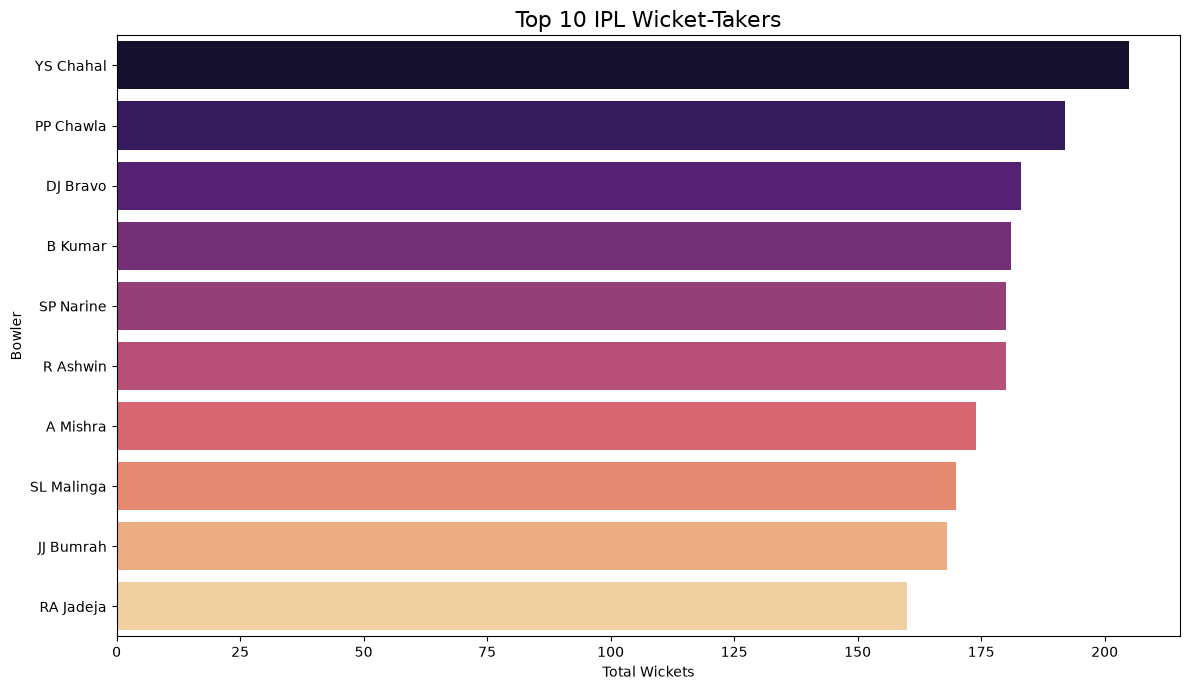

In [28]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_wicket_takers,
    x="wickets",
    y="bowler",
    hue="bowler",
    palette="magma",
    legend=False
)

plt.title("Top 10 IPL Wicket-Takers", fontsize=16)
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

In [29]:
qualified_average_bowlers = bowling_stats[
    (bowling_stats["legal_balls"] >= 500) &
    (bowling_stats["wickets"] >= 50)
]

top_10_bowling_average = qualified_average_bowlers.sort_values(
    by="bowling_average",
    ascending=True
).head(10)

print(top_10_bowling_average[
    ["bowler", "wickets", "runs_conceded",
     "bowling_average", "economy_rate"]
])

          bowler  wickets  runs_conceded  bowling_average  economy_rate
438   SL Malinga      170           3364            19.79          7.14
174  Imran Tahir       82           1703            20.77          7.76
212     K Rabada      120           2577            21.48          8.45
398  Rashid Khan      149           3267            21.93          6.83
193    JJ Bumrah      168           3743            22.28          7.30
273     MA Starc       51           1137            22.29          8.21
524    YS Chahal      205           4602            22.45          7.84
289     MM Patel       74           1698            22.95          7.52
29    AD Russell      115           2646            23.01          9.36
162     HV Patel      135           3148            23.32          8.74


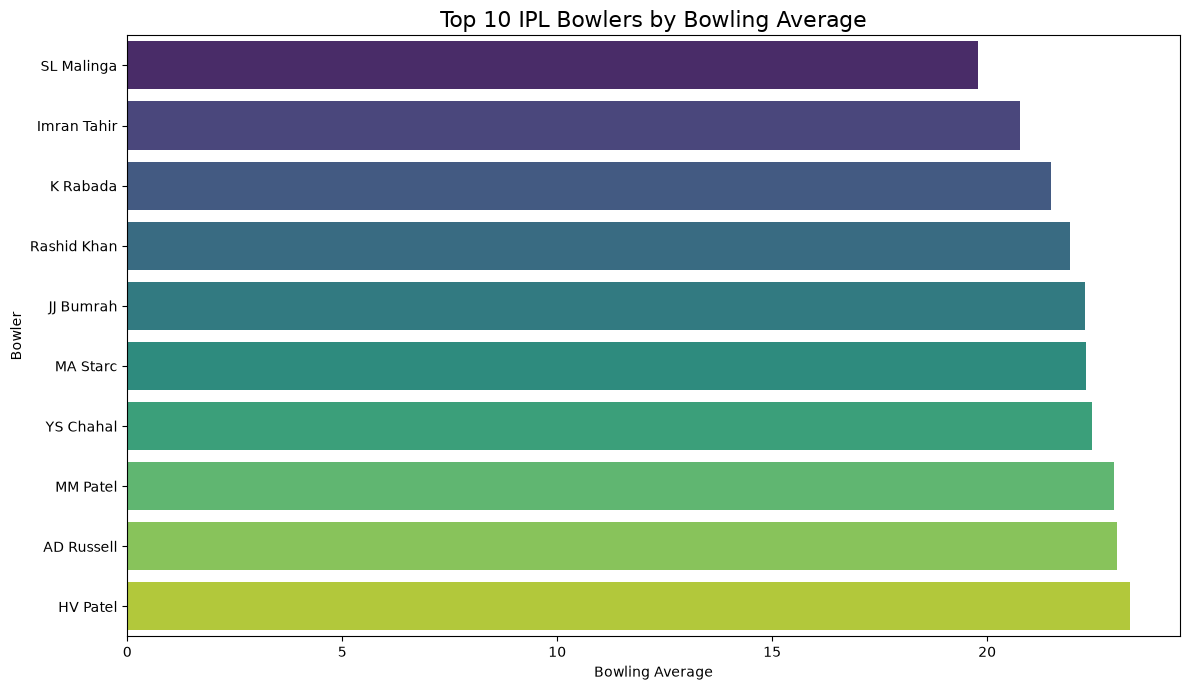

In [30]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_bowling_average,
    x="bowling_average",
    y="bowler",
    hue="bowler",
    palette="viridis",
    legend=False
)

plt.title("Top 10 IPL Bowlers by Bowling Average", fontsize=16)
plt.xlabel("Bowling Average")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

In [31]:
all_rounder_stats = batting_stats.merge(
    bowler_wickets,
    left_on="batter",
    right_on="bowler",
    how="inner"
)

all_rounder_stats = all_rounder_stats[
    ["batter", "total_runs", "wickets"]
]

all_rounder_stats = all_rounder_stats.rename(
    columns={"batter": "player"}
)

print(all_rounder_stats.head(10))

           player  total_runs  wickets
0  A Ashish Reddy         280       18
1        A Badoni         634        2
2      A Chandila           4       11
3     A Choudhary          25        5
4      A Flintoff          62        2
5        A Kamboj           2        2
6        A Kumble          35       45
7        A Mishra         381      174
8        A Mithun          34        7
9         A Nehra          41      106


In [32]:
qualified_all_rounders = all_rounder_stats[
    (all_rounder_stats["total_runs"] >= 500) &
    (all_rounder_stats["wickets"] >= 20)
]

qualified_all_rounders = qualified_all_rounders.sort_values(
    by="total_runs",
    ascending=False
)

print(qualified_all_rounders.head(15))

           player  total_runs  wickets
338      SK Raina        5536       25
348     SR Watson        3880       92
176    KA Pollard        3437       69
405     YK Pathan        3222       42
291     RA Jadeja        2959      160
124    GJ Maxwell        2772       37
409  Yuvraj Singh        2754       36
128     HH Pandya        2534       64
25     AD Russell        2488      115
156     JH Kallis        2427       65
110      DR Smith        2385       26
163     JP Duminy        2029       23
233    MP Stoinis        1866       43
37       AR Patel        1653      123
178     KH Pandya        1647       76


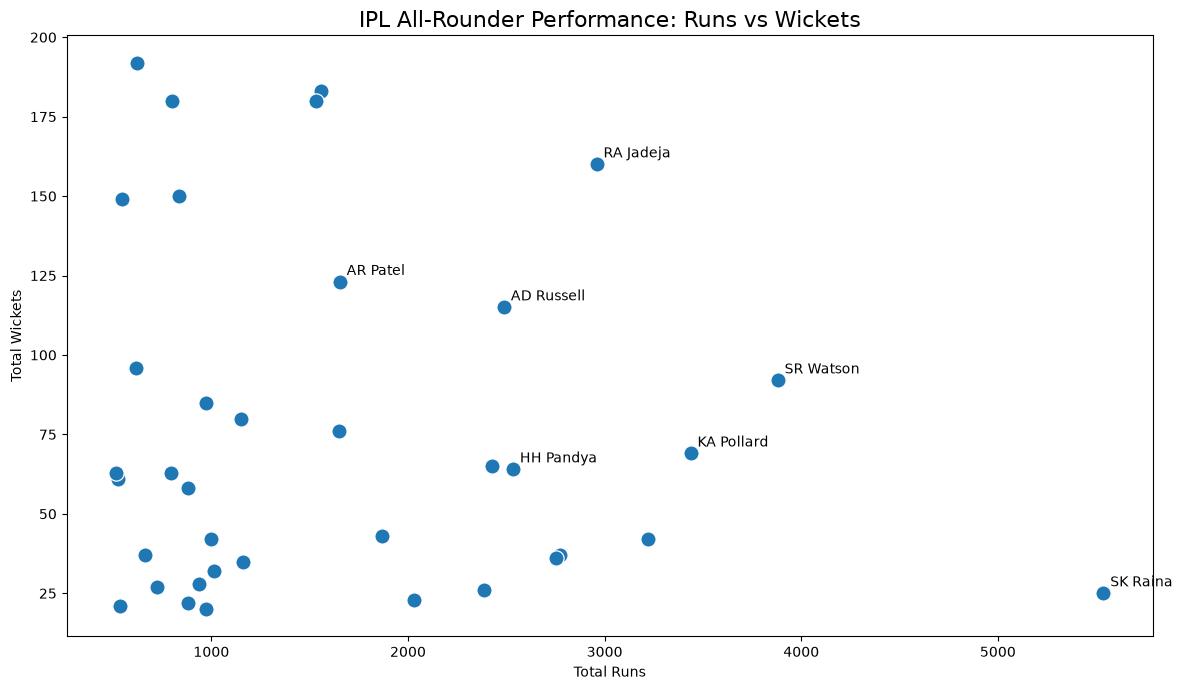

In [34]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=qualified_all_rounders,
    x="total_runs",
    y="wickets",
    s=120
)

plt.title("IPL All-Rounder Performance: Runs vs Wickets", fontsize=16)
plt.xlabel("Total Runs")
plt.ylabel("Total Wickets")

notable_players = [
    "SK Raina",
    "SR Watson",
    "KA Pollard",
    "RA Jadeja",
    "HH Pandya",
    "AD Russell",
    "AR Patel"
]

for _, row in qualified_all_rounders[
    qualified_all_rounders["player"].isin(notable_players)
].iterrows():

    plt.annotate(
        row["player"],
        (row["total_runs"], row["wickets"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

In [35]:
print(deliveries["inning"].value_counts().sort_index())

inning
1    135018
2    125741
3        77
4        72
5         8
6         4
Name: count, dtype: int64


In [36]:
team_scores = deliveries[
    deliveries["inning"].isin([1, 2])
].groupby("batting_team").agg(
    total_runs=("total_runs", "sum")
).reset_index()

team_scores = team_scores.sort_values(
    by="total_runs",
    ascending=False
)

print(team_scores)

                   batting_team  total_runs
10               Mumbai Indians       42133
8         Kolkata Knight Riders       39295
0           Chennai Super Kings       38620
16  Royal Challengers Bangalore       37651
13             Rajasthan Royals       34712
6               Kings XI Punjab       30017
18          Sunrisers Hyderabad       29034
3              Delhi Daredevils       24285
2                Delhi Capitals       14879
1               Deccan Chargers       11463
12                 Punjab Kings        9536
5                Gujarat Titans        7757
9          Lucknow Super Giants        7510
11                Pune Warriors        6358
4                 Gujarat Lions        4856
17  Royal Challengers Bengaluru        2930
14       Rising Pune Supergiant        2470
15      Rising Pune Supergiants        2063
7          Kochi Tuskers Kerala        1901


In [37]:
team_name_mapping = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiant": "Rising Pune Supergiants"
}

deliveries["batting_team_clean"] = (
    deliveries["batting_team"].replace(team_name_mapping)
)

In [38]:
team_scores = deliveries[
    deliveries["inning"].isin([1, 2])
].groupby("batting_team_clean").agg(
    total_runs=("total_runs", "sum")
).reset_index()

team_scores = team_scores.sort_values(
    by="total_runs",
    ascending=False
)

print(team_scores)

             batting_team_clean  total_runs
8                Mumbai Indians       42133
13  Royal Challengers Bengaluru       40581
10                 Punjab Kings       39553
6         Kolkata Knight Riders       39295
2                Delhi Capitals       39164
0           Chennai Super Kings       38620
11             Rajasthan Royals       34712
14          Sunrisers Hyderabad       29034
1               Deccan Chargers       11463
4                Gujarat Titans        7757
7          Lucknow Super Giants        7510
9                 Pune Warriors        6358
3                 Gujarat Lions        4856
12      Rising Pune Supergiants        4533
5          Kochi Tuskers Kerala        1901


In [39]:
team_innings = deliveries[
    deliveries["inning"].isin([1, 2])
][
    ["match_id", "inning", "batting_team_clean"]
].drop_duplicates()

team_innings = team_innings.groupby(
    "batting_team_clean"
).size().reset_index(name="innings_played")

print(team_innings)

             batting_team_clean  innings_played
0           Chennai Super Kings             237
1               Deccan Chargers              75
2                Delhi Capitals             252
3                 Gujarat Lions              30
4                Gujarat Titans              45
5          Kochi Tuskers Kerala              14
6         Kolkata Knight Riders             251
7          Lucknow Super Giants              44
8                Mumbai Indians             261
9                 Pune Warriors              45
10                 Punjab Kings             246
11             Rajasthan Royals             220
12      Rising Pune Supergiants              30
13  Royal Challengers Bengaluru             255
14          Sunrisers Hyderabad             182


In [40]:
team_performance = team_scores.merge(
    team_innings,
    on="batting_team_clean",
    how="inner"
)

team_performance["average_runs"] = (
    team_performance["total_runs"] /
    team_performance["innings_played"]
).round(2)

team_performance = team_performance.sort_values(
    by="average_runs",
    ascending=False
)

print(team_performance)

             batting_team_clean  total_runs  innings_played  average_runs
9                Gujarat Titans        7757              45        172.38
10         Lucknow Super Giants        7510              44        170.68
5           Chennai Super Kings       38620             237        162.95
12                Gujarat Lions        4856              30        161.87
0                Mumbai Indians       42133             261        161.43
2                  Punjab Kings       39553             246        160.78
7           Sunrisers Hyderabad       29034             182        159.53
1   Royal Challengers Bengaluru       40581             255        159.14
6              Rajasthan Royals       34712             220        157.78
3         Kolkata Knight Riders       39295             251        156.55
4                Delhi Capitals       39164             252        155.41
8               Deccan Chargers       11463              75        152.84
13      Rising Pune Supergiants       

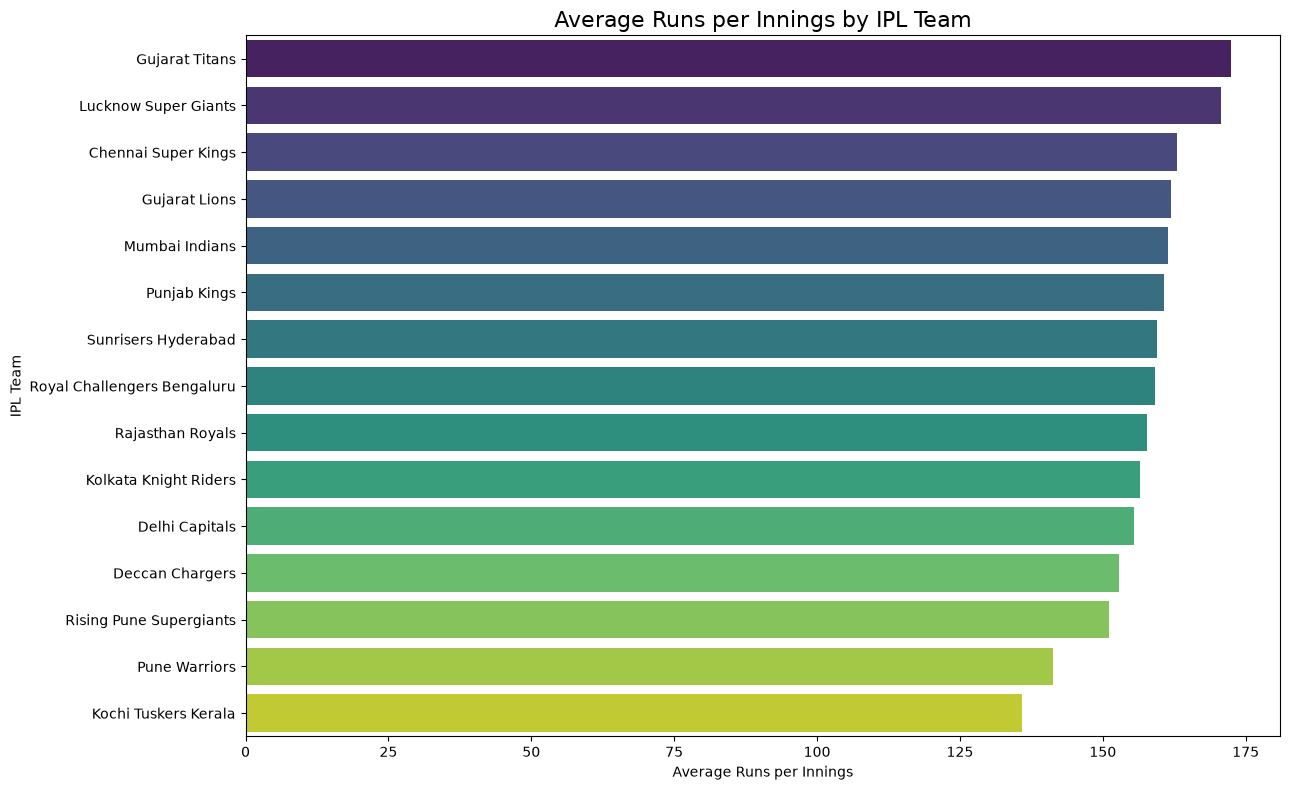

In [41]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=team_performance,
    x="average_runs",
    y="batting_team_clean",
    hue="batting_team_clean",
    palette="viridis",
    legend=False
)

plt.title("Average Runs per Innings by IPL Team", fontsize=16)
plt.xlabel("Average Runs per Innings")
plt.ylabel("IPL Team")

plt.tight_layout()
plt.show()

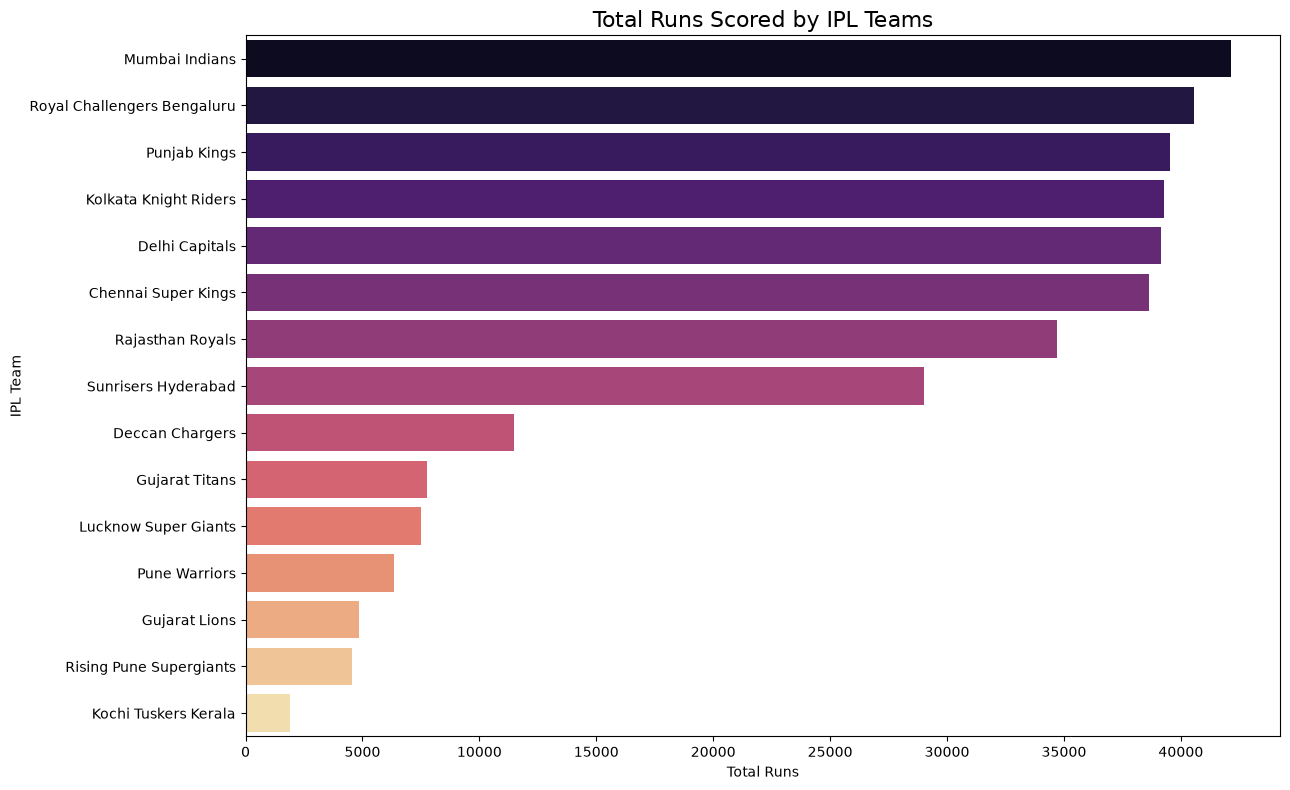

In [42]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=team_scores,
    x="total_runs",
    y="batting_team_clean",
    hue="batting_team_clean",
    palette="magma",
    legend=False
)

plt.title("Total Runs Scored by IPL Teams", fontsize=16)
plt.xlabel("Total Runs")
plt.ylabel("IPL Team")

plt.tight_layout()
plt.show()

In [43]:
venue_matches = matches.groupby("venue").agg(
    total_matches=("id", "count")
).reset_index()

venue_matches = venue_matches.sort_values(
    by="total_matches",
    ascending=False
)

print(venue_matches.head(15))

                                         venue  total_matches
14                                Eden Gardens             77
55                            Wankhede Stadium             73
23                       M Chinnaswamy Stadium             65
16                            Feroz Shah Kotla             60
42   Rajiv Gandhi International Stadium, Uppal             49
27             MA Chidambaram Stadium, Chepauk             48
46                      Sawai Mansingh Stadium             47
13         Dubai International Cricket Stadium             46
56                    Wankhede Stadium, Mumbai             45
40  Punjab Cricket Association Stadium, Mohali             35
50                        Sheikh Zayed Stadium             29
28    MA Chidambaram Stadium, Chepauk, Chennai             28
49                     Sharjah Cricket Stadium             28
32            Narendra Modi Stadium, Ahmedabad             24
30     Maharashtra Cricket Association Stadium             22


In [44]:
print(sorted(matches["venue"].dropna().unique()))

['Arun Jaitley Stadium', 'Arun Jaitley Stadium, Delhi', 'Barabati Stadium', 'Barsapara Cricket Stadium, Guwahati', 'Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow', 'Brabourne Stadium', 'Brabourne Stadium, Mumbai', 'Buffalo Park', 'De Beers Diamond Oval', 'Dr DY Patil Sports Academy', 'Dr DY Patil Sports Academy, Mumbai', 'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium', 'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam', 'Dubai International Cricket Stadium', 'Eden Gardens', 'Eden Gardens, Kolkata', 'Feroz Shah Kotla', 'Green Park', 'Himachal Pradesh Cricket Association Stadium', 'Himachal Pradesh Cricket Association Stadium, Dharamsala', 'Holkar Cricket Stadium', 'JSCA International Stadium Complex', 'Kingsmead', 'M Chinnaswamy Stadium', 'M Chinnaswamy Stadium, Bengaluru', 'M.Chinnaswamy Stadium', 'MA Chidambaram Stadium', 'MA Chidambaram Stadium, Chepauk', 'MA Chidambaram Stadium, Chepauk, Chennai', 'Maharaja Yadavindra Singh Internation

In [45]:
venue_mapping = {
    "Feroz Shah Kotla": "Arun Jaitley Stadium",
    "Arun Jaitley Stadium, Delhi": "Arun Jaitley Stadium",

    "Wankhede Stadium, Mumbai": "Wankhede Stadium",

    "M Chinnaswamy Stadium, Bengaluru": "M Chinnaswamy Stadium",
    "M.Chinnaswamy Stadium": "M Chinnaswamy Stadium",

    "MA Chidambaram Stadium": "MA Chidambaram Stadium",
    "MA Chidambaram Stadium, Chepauk": "MA Chidambaram Stadium",
    "MA Chidambaram Stadium, Chepauk, Chennai": "MA Chidambaram Stadium",

    "Eden Gardens, Kolkata": "Eden Gardens",

    "Brabourne Stadium, Mumbai": "Brabourne Stadium",

    "Dr DY Patil Sports Academy, Mumbai": "Dr DY Patil Sports Academy",

    "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam":
        "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium",

    "Himachal Pradesh Cricket Association Stadium, Dharamsala":
        "Himachal Pradesh Cricket Association Stadium",

    "Maharashtra Cricket Association Stadium, Pune":
        "Maharashtra Cricket Association Stadium",

    "Punjab Cricket Association IS Bindra Stadium, Mohali":
        "Punjab Cricket Association IS Bindra Stadium",
    "Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh":
        "Punjab Cricket Association IS Bindra Stadium",
    "Punjab Cricket Association Stadium, Mohali":
        "Punjab Cricket Association IS Bindra Stadium",

    "Rajiv Gandhi International Stadium, Uppal":
        "Rajiv Gandhi International Stadium",
    "Rajiv Gandhi International Stadium, Uppal, Hyderabad":
        "Rajiv Gandhi International Stadium",

    "Sawai Mansingh Stadium, Jaipur": "Sawai Mansingh Stadium",

    "Sardar Patel Stadium, Motera": "Narendra Modi Stadium, Ahmedabad",

    "Zayed Cricket Stadium, Abu Dhabi": "Sheikh Zayed Stadium"
}

matches["venue_clean"] = matches["venue"].replace(venue_mapping)

venue_matches = matches.groupby("venue_clean").agg(
    total_matches=("id", "count")
).reset_index()

venue_matches = venue_matches.sort_values(
    by="total_matches",
    ascending=False
)

print(venue_matches.head(15))

                                     venue_clean  total_matches
36                              Wankhede Stadium            118
16                         M Chinnaswamy Stadium             94
10                                  Eden Gardens             93
0                           Arun Jaitley Stadium             90
17                        MA Chidambaram Stadium             85
26            Rajiv Gandhi International Stadium             77
25  Punjab Cricket Association IS Bindra Stadium             61
28                        Sawai Mansingh Stadium             57
9            Dubai International Cricket Stadium             46
7                     Dr DY Patil Sports Academy             37
31                          Sheikh Zayed Stadium             37
20              Narendra Modi Stadium, Ahmedabad             36
19       Maharashtra Cricket Association Stadium             35
30                       Sharjah Cricket Stadium             28
4                              Brabourne

In [46]:
venue_deliveries = deliveries.merge(
    matches[["id", "venue_clean"]],
    left_on="match_id",
    right_on="id",
    how="left"
)

print(venue_deliveries[
    ["match_id", "venue_clean", "inning", "total_runs"]
].head(10))

   match_id            venue_clean  inning  total_runs
0    335982  M Chinnaswamy Stadium       1           1
1    335982  M Chinnaswamy Stadium       1           0
2    335982  M Chinnaswamy Stadium       1           1
3    335982  M Chinnaswamy Stadium       1           0
4    335982  M Chinnaswamy Stadium       1           0
5    335982  M Chinnaswamy Stadium       1           0
6    335982  M Chinnaswamy Stadium       1           1
7    335982  M Chinnaswamy Stadium       1           0
8    335982  M Chinnaswamy Stadium       1           4
9    335982  M Chinnaswamy Stadium       1           4


In [47]:
venue_innings_scores = venue_deliveries[
    venue_deliveries["inning"].isin([1, 2])
].groupby(
    ["match_id", "venue_clean", "inning"]
).agg(
    innings_score=("total_runs", "sum")
).reset_index()

print(venue_innings_scores.head(10))

   match_id                                   venue_clean  inning  \
0    335982                         M Chinnaswamy Stadium       1   
1    335982                         M Chinnaswamy Stadium       2   
2    335983  Punjab Cricket Association IS Bindra Stadium       1   
3    335983  Punjab Cricket Association IS Bindra Stadium       2   
4    335984                          Arun Jaitley Stadium       1   
5    335984                          Arun Jaitley Stadium       2   
6    335985                              Wankhede Stadium       1   
7    335985                              Wankhede Stadium       2   
8    335986                                  Eden Gardens       1   
9    335986                                  Eden Gardens       2   

   innings_score  
0            222  
1             82  
2            240  
3            207  
4            129  
5            132  
6            165  
7            166  
8            110  
9            112  


In [48]:
venue_performance = venue_innings_scores.groupby(
    "venue_clean"
).agg(
    total_runs=("innings_score", "sum"),
    innings_played=("innings_score", "count"),
    average_runs=("innings_score", "mean")
).reset_index()

venue_performance["average_runs"] = (
    venue_performance["average_runs"].round(2)
)

venue_performance = venue_performance.sort_values(
    by="average_runs",
    ascending=False
)

print(venue_performance.head(15))

                                          venue_clean  total_runs  \
4                                   Brabourne Stadium        9305   
2                 Barsapara Cricket Stadium, Guwahati        1019   
12       Himachal Pradesh Cricket Association Stadium        4412   
18  Maharaja Yadavindra Singh International Cricke...        1675   
27             Saurashtra Cricket Association Stadium        3316   
20                   Narendra Modi Stadium, Ahmedabad       11896   
36                                   Wankhede Stadium       38977   
16                              M Chinnaswamy Stadium       30686   
25       Punjab Cricket Association IS Bindra Stadium       19864   
1                                    Barabati Stadium        2278   
11                                         Green Park        1298   
0                                Arun Jaitley Stadium       29038   
10                                       Eden Gardens       29743   
13                             Hol

In [49]:
qualified_venues = venue_performance[
    venue_performance["innings_played"] >= 20
]

top_10_venues = qualified_venues.sort_values(
    by="average_runs",
    ascending=False
).head(10)

print(top_10_venues)

                                          venue_clean  total_runs  \
4                                   Brabourne Stadium        9305   
12       Himachal Pradesh Cricket Association Stadium        4412   
27             Saurashtra Cricket Association Stadium        3316   
20                   Narendra Modi Stadium, Ahmedabad       11896   
36                                   Wankhede Stadium       38977   
16                              M Chinnaswamy Stadium       30686   
25       Punjab Cricket Association IS Bindra Stadium       19864   
0                                Arun Jaitley Stadium       29038   
10                                       Eden Gardens       29743   
3   Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...        4294   

    innings_played  average_runs  
4               54        172.31  
12              26        169.69  
27              20        165.80  
20              72        165.22  
36             236        165.16  
16             187        164.

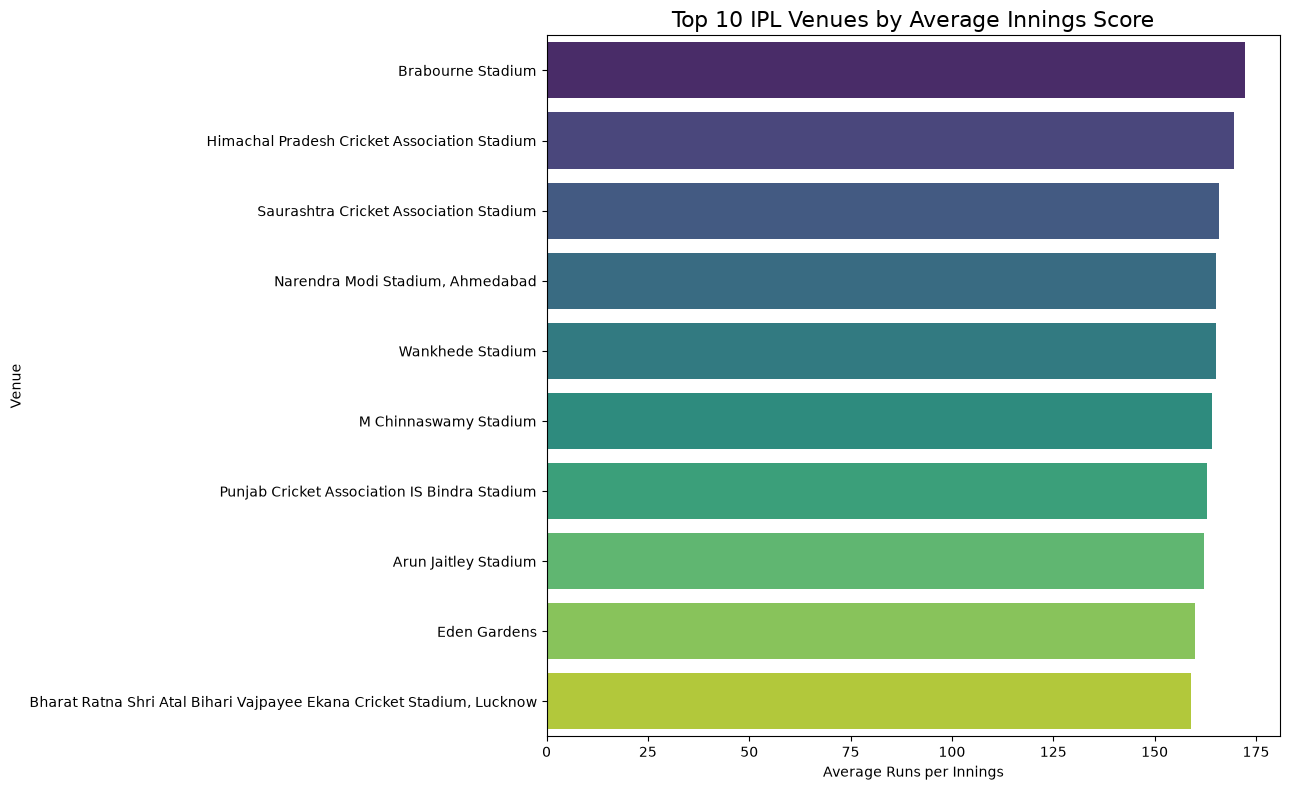

In [50]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_10_venues,
    x="average_runs",
    y="venue_clean",
    hue="venue_clean",
    palette="viridis",
    legend=False
)

plt.title("Top 10 IPL Venues by Average Innings Score", fontsize=16)
plt.xlabel("Average Runs per Innings")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

# IPLytics — Advanced Analysis & Cricket Insights

## 1. Objective

The objective of  was to perform advanced IPL data analysis and extract meaningful cricket insights using Pandas, NumPy, Matplotlib, and Seaborn.

The analysis focused on five major areas:

1. Batting Strike Rates
2. Bowling Economy Rates
3. Player Performance Comparisons
4. Team Scoring Patterns
5. Venue Analysis

## 2. Batting Strike Rate Analysis

Calculated total runs, balls faced, and batting strike rates for individual players.

### Formula

Strike Rate = (Total Runs / Balls Faced) × 100

### Analysis Performed

- Calculated total runs scored by each batsman.
- Calculated balls faced, excluding wide deliveries.
- Calculated batting strike rates.
- Identified the Top 10 batsmen by strike rate (minimum 500 balls faced).
- Identified the Top 10 run scorers.

### Key Findings

- Virat Kohli recorded the highest total runs with 8,014.
- Andre Russell recorded the highest strike rate among qualified batsmen at 174.84.
- H Klaasen and Sunil Narine also featured among the highest strike-rate players.

### Visualizations

- Top 10 IPL Batsmen by Strike Rate.
- Top 10 IPL Run Scorers.

## 3. Bowling Economy Rate Analysis

Analyzed bowling performance using runs conceded, legal balls, wickets, economy rate, and bowling average.

### Formulas

Economy Rate = (Runs Conceded × 6) / Legal Balls Bowled

Bowling Average = Runs Conceded / Wickets Taken

### Analysis Performed

- Calculated runs conceded by each bowler.
- Excluded byes, legbyes, and penalty extras from bowler-conceded runs.
- Identified legal deliveries by excluding wides and no-balls.
- Calculated wickets credited to bowlers.
- Calculated bowling economy rates and bowling averages.
- Identified the Top 10 wicket-takers.
- Identified the Top 10 bowlers by economy rate and bowling average.

### Key Findings

- Yuzvendra Chahal recorded the highest number of wickets with 205.
- Sunil Narine recorded an economy rate of 6.74 among the qualified top wicket-takers.
- Lasith Malinga recorded the lowest bowling average among the qualified bowlers at 19.79.
- Rashid Khan recorded an economy rate of 6.83.

### Qualification Criteria

- Economy analysis: Minimum 500 legal balls.
- Wicket-taker analysis: Minimum 500 legal balls.
- Bowling average analysis: Minimum 500 legal balls and 50 wickets.

### Visualizations

- Top 10 IPL Bowlers by Economy Rate.
- Top 10 IPL Wicket-Takers.
- Top 10 IPL Bowlers by Bowling Average.

## 4. Player Performance Comparisons

Compared batting and bowling contributions to identify players who contributed in both departments.

### Analysis Performed

- Combined batting statistics and bowler wicket statistics.
- Used an inner join on player names.
- Filtered players with at least 500 runs and 20 wickets.
- Compared total runs and wickets taken.

### Key Findings

| Player | Total Runs | Wickets |
|---|---:|---:|
| SK Raina | 5,536 | 25 |
| SR Watson | 3,880 | 92 |
| KA Pollard | 3,437 | 69 |
| RA Jadeja | 2,959 | 160 |
| HH Pandya | 2,534 | 64 |
| AD Russell | 2,488 | 115 |
| AR Patel | 1,653 | 123 |

- Suresh Raina recorded the highest batting contribution in the qualified group.
- Ravindra Jadeja demonstrated a strong all-round contribution with 2,959 runs and 160 wickets.
- Andre Russell recorded 2,488 runs and 115 wickets.

### Visualization

- IPL All-Rounder Performance: Runs vs Wickets (Scatter Plot).

## 5. Team Scoring Patterns

Analyzed team-wise scoring performance across regular IPL innings.

### Analysis Performed

- Inspected innings categories.
- Excluded super-over innings (innings 3–6).
- Standardized historical team names.
- Calculated total runs scored by each franchise.
- Counted regular innings played by each team.
- Calculated average runs per innings.
- Compared cumulative runs and average scoring performance.

### Historical Team Name Standardization

| Previous Name | Standardized Name |
|---|---|
| Delhi Daredevils | Delhi Capitals |
| Kings XI Punjab | Punjab Kings |
| Royal Challengers Bangalore | Royal Challengers Bengaluru |
| Rising Pune Supergiant | Rising Pune Supergiants |

### Key Findings

**Highest Total Runs**

| Team | Total Runs |
|---|---:|
| Mumbai Indians | 42,133 |
| Royal Challengers Bengaluru | 40,581 |
| Punjab Kings | 39,553 |
| Kolkata Knight Riders | 39,295 |
| Delhi Capitals | 39,164 |

**Highest Average Runs per Innings**

| Team | Average Runs |
|---|---:|
| Gujarat Titans | 172.38 |
| Lucknow Super Giants | 170.68 |
| Chennai Super Kings | 162.95 |
| Gujarat Lions | 161.87 |
| Mumbai Indians | 161.43 |

- Mumbai Indians recorded the highest cumulative runs.
- Gujarat Titans recorded the highest average runs per innings.
- Cumulative runs and average scoring provide different perspectives on team performance.

### Visualizations

- Total Runs Scored by IPL Teams.
- Average Runs per Innings by IPL Team.

## 6. Venue Analysis

Analyzed IPL match distribution and scoring performance across different venues.

### Analysis Performed

- Identified venues hosting the most IPL matches.
- Inspected historical venue name variations.
- Standardized venue names.
- Calculated total matches hosted by each venue.
- Merged venue information with ball-by-ball delivery data.
- Calculated individual innings scores at each venue.
- Calculated total runs, innings played, and average runs per innings.
- Selected venues with at least 20 innings for meaningful comparison.

### Venue Name Standardization

Examples of standardized venue names:

| Previous Name | Standardized Name |
|---|---|
| Feroz Shah Kotla | Arun Jaitley Stadium |
| Wankhede Stadium, Mumbai | Wankhede Stadium |
| M.Chinnaswamy Stadium | M Chinnaswamy Stadium |
| Eden Gardens, Kolkata | Eden Gardens |
| MA Chidambaram Stadium, Chepauk | MA Chidambaram Stadium |
| Sardar Patel Stadium, Motera | Narendra Modi Stadium, Ahmedabad |

### Most Frequently Used Venues

| Venue | Matches |
|---|---:|
| Wankhede Stadium | 118 |
| M Chinnaswamy Stadium | 94 |
| Eden Gardens | 93 |
| Arun Jaitley Stadium | 90 |
| MA Chidambaram Stadium | 85 |
| Rajiv Gandhi International Stadium | 77 |
| Punjab Cricket Association IS Bindra Stadium | 61 |
| Sawai Mansingh Stadium | 57 |

### Highest Average Scoring Venues

Only venues with at least 20 innings were considered.

| Venue | Average Runs | Innings |
|---|---:|---:|
| Brabourne Stadium | 172.31 | 54 |
| Himachal Pradesh Cricket Association Stadium | 169.69 | 26 |
| Saurashtra Cricket Association Stadium | 165.80 | 20 |
| Narendra Modi Stadium | 165.22 | 72 |
| Wankhede Stadium | 165.16 | 236 |
| M Chinnaswamy Stadium | 164.10 | 187 |
| Punjab Cricket Association IS Bindra Stadium | 162.82 | 122 |
| Arun Jaitley Stadium | 162.22 | 179 |
| Eden Gardens | 159.91 | 186 |
| Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium | 159.04 | 27 |

### Key Findings

- Wankhede Stadium hosted the most matches in the standardized dataset, with 118.
- Brabourne Stadium recorded the highest average innings score among venues with at least 20 innings, at 172.31.
- Venue scoring averages vary across stadiums.
- The number of innings is important when interpreting venue averages.

### Visualization

- Top 10 IPL Venues by Average Innings Score.

## 7. Visualizations Created

A total of 10 visual